# Week 8 Take Home

This week has two parts:

| Part | Lessons | Take-home work |
|------|---------|----------------|
| **A. Grouping & Aggregating Data** | `1-Grouping & Aggregating Data/` (notebooks 1–4) | Project 4 below + the notebook task solutions |
| **B. Data Visualization** | `2-Data Visualization (Seaborn & Matplotlib)/` (videos + scripts) | Re-create the plots from the videos using the Part A milk data: a histogram, a KDE plot, a box/violin plot, a regression plot and a heatmap. Add them at the end of this notebook. |

Part A data comes from the cohort database (schema `week09`). See `Data Access (SQL).md`.

---
# Part A: Grouping & Aggregating Data

## Project 4: Exploring the UK's milk imports and exports

A country's economy depends, sometimes heavily, on its exports and imports. The United Nations Comtrade database provides data on global trade. It will be used to analyse the UK's imports and exports of milk and cream in 2015:

- How much does the UK export and import and is the balance positive (more exports than imports)? 
- Which are the main trading partners, i.e. from/to which countries does the UK import/export the most?
- Which are the regular customers, i.e. which countries buy milk from the UK every month?
- Which countries does the UK both import from and export to?

In [22]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

from pandas import *
%matplotlib inline

## Getting and preparing the data

The data is obtained from the [United Nations Comtrade](http://comtrade.un.org/data/) website, by selecting the following configuration:

- Type of Product: goods
- Frequency: monthly 
- Periods: January to May of 2015
- Reporter: United Kingdom
- Partners: all
- Flows: imports and exports
- HS (as reported) commodity codes: 0401 (Milk and cream, neither concentrated nor sweetened) and 0402 (Milk and cream, concentrated or sweetened)

Clicking on 'Preview' results in a message that the data exceeds 500 rows. Data was downloaded using the *Download CSV* button and the download file renamed appropriately.

In [25]:
LOCATION = 'comtrade_milk_uk_jan_jul_15.csv'

The data can also be downloaded directly from Comtrade using the "View API Call" URL, modified in two ways:

- `max=500` is increased to `max=5000` to make sure all data is loaded,
- `&fmt=csv` is added at the end to obtain the data in CSV format.

In [28]:
# LOCATION = 'http://comtrade.un.org/api/get?max=5000&type=C&freq=M&px=HS&ps=201505%2C201504%2C201503%2C201502%2C201501&r=826&p=all&rg=1%2C2&cc=0401%2C0402&fmt=csv'

On reading in the data, the commodity code has to be read as a string, to not lose the leading zero.

In [41]:
import sys, pathlib
from dotenv import load_dotenv  

# 1. Find the project root directory
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))

# 2. Load the credentials from your .env file
load_dotenv(_p / ".env")  

# 3. Import and run your query
from db.dataraflow_db import run_query
milk = run_query("SELECT * FROM week09.comtrade_milk_uk_jan_jul_15")
milk.head(2)


,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
0,HS,2015,201501,January 2015,4,0,1,Imports,826,United Kingdom,...,None,None,None,None,17062015,None,14104602,None,None,0
1,HS,2015,201501,January 2015,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,56302663,None,26259792,None,None,0


The data only covers the first five months of 2015. Most columns are irrelevant for this analysis, or contain always the same value, like the year and reporter columns. The commodity code is transformed into a short but descriptive text and only the relevant columns are selected.

In [44]:
def milkType(code):
    if code == '0401': # neither concentrated nor sweetened
        return 'unprocessed'
    if code == '0402': # concentrated or sweetened
        return 'processed' 
    return 'unknown'

COMMODITY = 'Milk and cream'
milk[COMMODITY] = milk['Commodity Code'].apply(milkType)
MONTH = 'Period'
PARTNER = 'Partner'
FLOW = 'Trade Flow'
VALUE = 'Trade Value (US$)'
headings = [MONTH, PARTNER, FLOW, COMMODITY, VALUE]
milk = milk[headings]
milk.head()

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
0,201501,World,Imports,unprocessed,14104602
1,201501,World,Exports,unprocessed,26259792
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271


The data contains the total imports and exports per month, under the 'World' partner. Those rows are removed to keep only the per-country data.

In [47]:
milk = milk[milk[PARTNER] != 'World']
milk.head()

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271
5,201501,Belgium,Exports,unprocessed,996031
6,201501,Bulgaria,Exports,unprocessed,191


## Total trade flow

To answer the first question, 'how much does the UK export and import and is the balance positive (more exports than imports)?',
the dataframe is split into two groups: exports from the UK and imports into the UK. The  trade values within each group are summed up to get the total trading.

In [50]:
grouped = milk.groupby([FLOW])
grouped[VALUE].aggregate(sum)

Trade Flow
Exports    265029661
Imports    156483978
Name: Trade Value (US$), dtype: int64

This shows a trade surplus of over 100 million dollars.

## Main trade partners

To address the second question, 'Which are the main trading partners, i.e. from/to which countries does the UK import/export the most?', the dataframe is split by country instead, and then each group aggregated for the total trade value. This is done separately for imports and exports. The result is sorted in descending order so that the main partners are at the top.

In [54]:
imports = milk[milk[FLOW] == 'Imports']
grouped = imports.groupby([PARTNER])
print('The UK imports from', len(grouped), 'countries.')
print('The 5 biggest exporters to the UK are:')
totalImports = grouped[VALUE].aggregate(sum).sort_values(inplace=False,ascending=False)
totalImports.head()

The UK imports from 21 countries.
The 5 biggest exporters to the UK are:


Partner
Ireland        46263897
France         28314091
Germany        21899123
Netherlands    17658912
Belgium        14325697
Name: Trade Value (US$), dtype: int64

The export values can be plotted as a bar chart, making differences between countries easier to see.

In [57]:
totalImports.head(10).plot(kind='barh')

<Axes: ylabel='Partner'>

In [59]:
exports = milk[milk[FLOW] == 'Exports']
grouped = exports.groupby([PARTNER])
print('The UK exports to', len(grouped), 'countries.')
print('The 5 biggest importers from the UK are:')
grouped[VALUE].aggregate(sum).sort_values(ascending=False,inplace=False).head()

The UK exports to 107 countries.
The 5 biggest importers from the UK are:


Partner
Ireland                 128155891
Netherlands              18018603
China                    14111163
Germany                  10828464
China, Hong Kong SAR      9482458
Name: Trade Value (US$), dtype: int64

## Regular importers

Given that there are two commodities, the third question, 'Which are the regular customers, i.e. which countries buy milk from the UK every month?', is meant in the sense that a regular customer imports both commodities every month. This means that if the exports dataframe is grouped by country, each group has exactly ten rows (two commodities bought each of the five months). To see the countries, only the first month of one commodity has to be listed, as by definition it's the same countries every month and for the other commodity.

In [62]:
def buysEveryMonth(group):
    return len(group) == 10

grouped = exports.groupby([PARTNER])
regular = grouped.filter(buysEveryMonth)
regular[(regular[MONTH] == 201501) & (regular[COMMODITY] == 'processed')]

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
268,201501,Belgium,Exports,processed,142610
271,201501,China,Exports,processed,1013141
275,201501,Cyprus,Exports,processed,6625
280,201501,Denmark,Exports,processed,107883
284,201501,France,Exports,processed,178262
287,201501,Germany,Exports,processed,2588380
292,201501,"China, Hong Kong SAR",Exports,processed,1110086
294,201501,Hungary,Exports,processed,2119
298,201501,Ireland,Exports,processed,4020981
300,201501,Italy,Exports,processed,23267


Just over 75% of the total UK exports are due to these regular customers.

In [65]:
regular[VALUE].sum() / exports[VALUE].sum()

0.7583526396315317

## Bi-directional trade

To address the fourth question, 
'Which countries does the UK both import from and export to?', a pivot table is used to list the total export and import value for each country. 

In [68]:
countries = pivot_table(milk, index=[PARTNER], columns=[FLOW], 
                        values=VALUE, aggfunc=sum)
countries.head()

Trade Flow,Exports,Imports
Partner,,
Algeria,8087885.0,NaN
Angola,2416129.0,NaN
Antigua and Barbuda,22218.0,NaN
"Areas, nes",51205.0,NaN
Australia,81644.0,NaN


Removing the rows with a missing value will result in only those countries with bi-directional trade flow with the UK.

In [71]:
countries.dropna()

Trade Flow,Exports,Imports
Partner,,
Austria,56279.0,780.0
Belgium,7209121.0,14325697.0
Czech Rep.,2590.0,486889.0
Denmark,335068.0,13681759.0
France,9381762.0,28314091.0
Germany,10828464.0,21899123.0
Hungary,71378.0,4762.0
Ireland,128155891.0,46263897.0
Italy,173689.0,321635.0


## Provide `1-Grouping & Aggregating Data/1.ipynb` Tasks Solutions below (Execute them)

In [74]:
# Grouping the milk dataset by Trade Flow and calculating the total trade value
grouped_flow = milk.groupby("Trade Flow")
print("Total Trade Value by Flow (US$):")
print(grouped_flow["Trade Value (US$)"].sum())

Total Trade Value by Flow (US$):
Trade Flow
Exports    265029661
Imports    156483978
Name: Trade Value (US$), dtype: int64


## Provide `1-Grouping & Aggregating Data/2.ipynb` Tasks Solutions below (Execute them)

In [77]:
# Multiple Aggregations (sum, mean, count) per Partner
partner_summary = milk.groupby("Partner")["Trade Value (US$)"].agg(
    ["sum", "mean", "count"])
print("Top 5 Partners by Total Trade Value:")
print(partner_summary.sort_values(by="sum", ascending=False).head())

Top 5 Partners by Total Trade Value:
                   sum        mean  count
Partner                                  
Ireland      174419788  8720989.40     20
France        37695853  1884792.65     20
Netherlands   35677515  1783875.75     20
Germany       32727587  1636379.35     20
Belgium       21534818  1076740.90     20


## Provide `1-Grouping & Aggregating Data/3.ipynb` Tasks Solutions below (Execute them)

In [80]:
# Task: Filtering Groups using groupby.filter()
# Find partners that have more than 20 recorded trade entries across the period
active_partners = milk.groupby("Partner").filter(lambda g: len(g) > 20)
print(f"Number of records from highly active partners: {len(active_partners)}")
print("Unique active partners:", active_partners["Partner"].nunique())

Number of records from highly active partners: 0
Unique active partners: 0


## Provide `1-Grouping & Aggregating Data/4.ipynb` Tasks Solutions below (Execute them)

In [83]:
# Create a pivot table showing total trade value by Partner (rows) and Trade Flow (columns)
trade_pivot = pivot_table(
    milk,
    index="Partner",
    columns="Trade Flow",
    values="Trade Value (US$)",
    aggfunc="sum",
    fill_value=0,
)
print("Pivot Table Preview (Imports vs Exports by Country):")
print(trade_pivot.head())

Pivot Table Preview (Imports vs Exports by Country):
Trade Flow           Exports  Imports
Partner                              
Algeria              8087885        0
Angola               2416129        0
Antigua and Barbuda    22218        0
Areas, nes             51205        0
Australia              81644        0


## Conclusions

The milk and cream trade of the UK from January to May 2015 was analysed in terms of which countries the UK mostly depends on for income (exports) and goods (imports). Over the period, the UK had a trade surplus of over 100 million US dollars.

Ireland is the main partner, but it imported from the UK almost the triple in value than it exported to the UK. 

The UK exported to over 100 countries during the period, but only imported from 21 countries, the main ones (top five by trade value) being geographically close. China and Hong Kong are the main importers that are not also main exporters. 

The UK is heavily dependent on its regular customers, the 16 countries that buy all types of milk and cream every month. They contribute three quarters of the total export value.

The UK has bi-directional trade (i.e. both exports and imports) with 20 countries, although for some the trade value (in US dollars) is suspiciously low, which raises questions about the data's accuracy.


## Now repeat the analysis with your own data gotten from Comtrade website

---
# Part B: Data Visualization

Add your seaborn/matplotlib plots below. Use the milk trade data from Part A. Give each plot a title and labelled axes, and write one sentence under it saying what it shows.

In [88]:
import matplotlib.pyplot as plt
import seaborn as sns

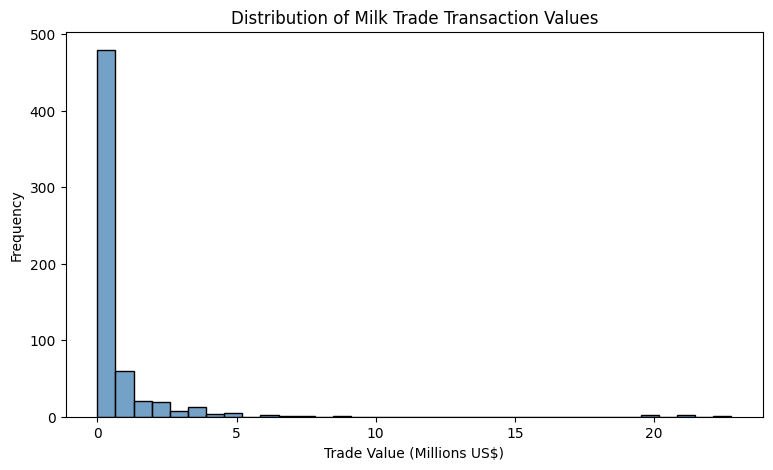

In [94]:
# Histogram
plt.figure(figsize=(9, 5))
sns.histplot(milk["Trade Value (US$)"] / 1e6, bins=35, color="steelblue", edgecolor="black")
plt.title("Distribution of Milk Trade Transaction Values")
plt.xlabel("Trade Value (Millions US$)")
plt.ylabel("Frequency")
plt.show()

This histogram shows that the vast majority of individual milk trade records have relatively low monetary values, with a long right-tail of high-value transactions.

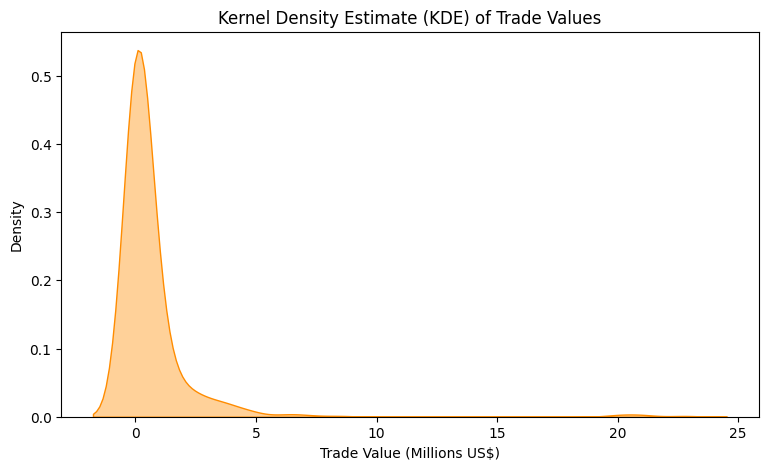

In [97]:
# KDE Plot
plt.figure(figsize=(9, 5))
sns.kdeplot(milk["Trade Value (US$)"] / 1e6, fill=True, color="darkorange", alpha=0.4)
plt.title("Kernel Density Estimate (KDE) of Trade Values")
plt.xlabel("Trade Value (Millions US$)")
plt.ylabel("Density")
plt.show()

This KDE plot highlights the continuous probability density function of trade values, emphasizing heavy skewness toward smaller transaction sizes.

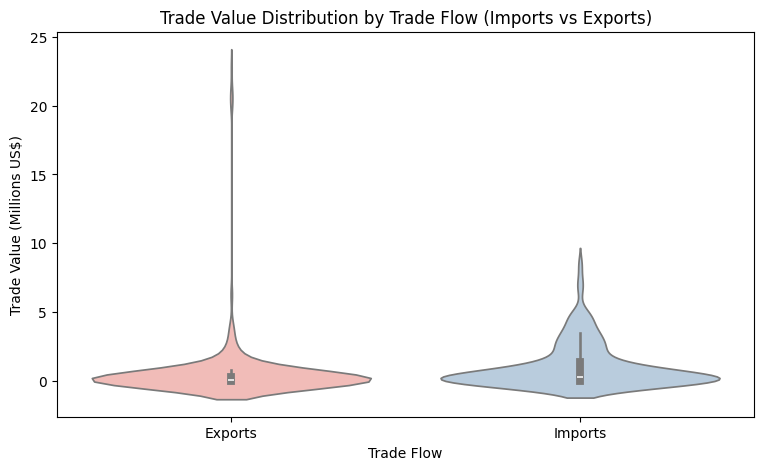

In [100]:
# Violin Plot
plt.figure(figsize=(9, 5))
sns.violinplot(
    x="Trade Flow",
    y=milk["Trade Value (US$)"] / 1e6,
    data=milk,
    palette="Pastel1",
    inner="box",
)
plt.title("Trade Value Distribution by Trade Flow (Imports vs Exports)")
plt.xlabel("Trade Flow")
plt.ylabel("Trade Value (Millions US$)")
plt.show()

This violin plot compares the statistical distribution, median, and interquartile spread of trade values between imports and exports.

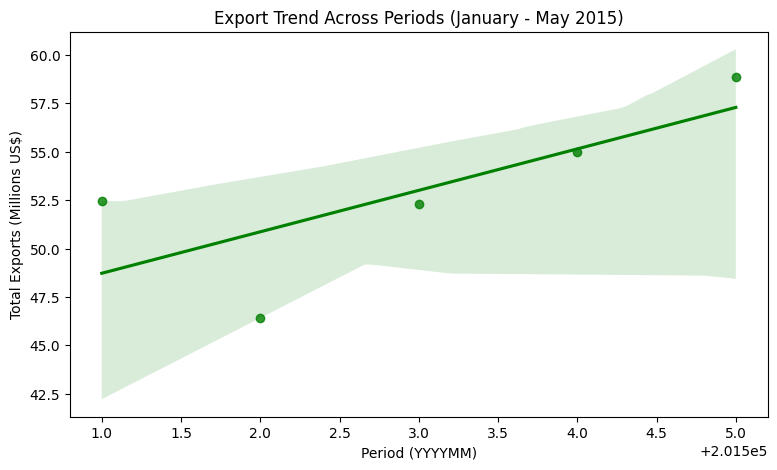

In [106]:
# Regression Plot (Monthly Trend)
monthly_trend = (
    milk.groupby(["Period", "Trade Flow"])["Trade Value (US$)"]
    .sum()
    .reset_index()
)
monthly_trend["Trade Value (Millions US$)"] = (
    monthly_trend["Trade Value (US$)"] / 1e6
)

plt.figure(figsize=(9, 5))
sns.regplot(
    data=monthly_trend[monthly_trend["Trade Flow"] == "Exports"],
    x="Period",
    y="Trade Value (Millions US$)",
    color="green",
    marker="o",
)
plt.title("Export Trend Across Periods (January - May 2015)")
plt.xlabel("Period (YYYYMM)")
plt.ylabel("Total Exports (Millions US$)")
plt.show()

This regression plot illustrates the trajectory and linear trend of total UK milk exports across the observed monthly periods.

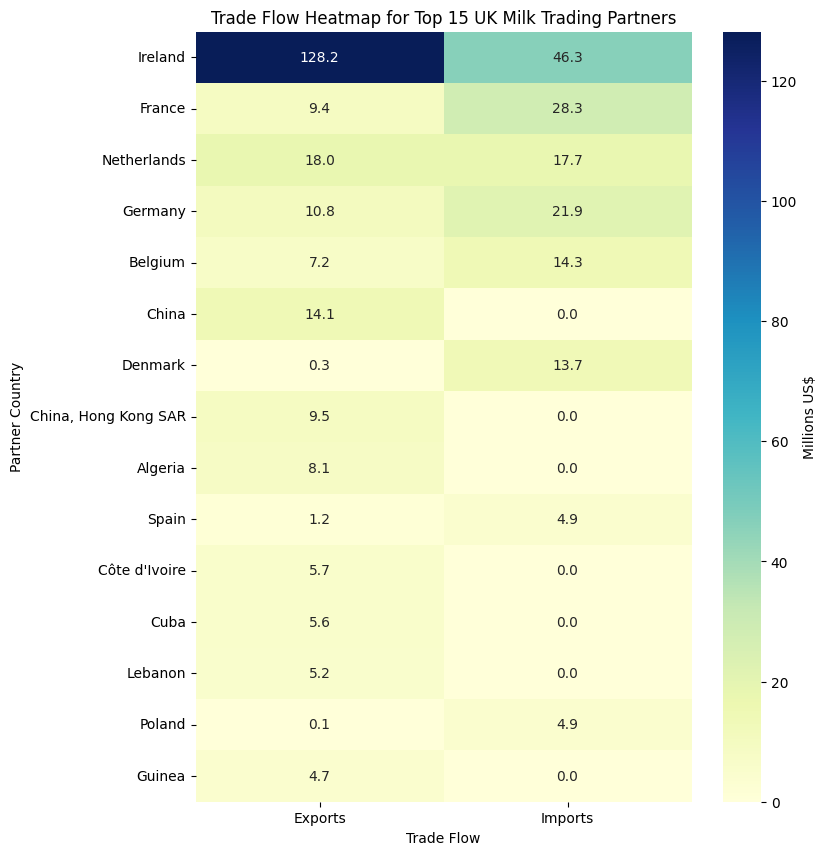

In [109]:
# Heatmap (Correlation or Pivot Heatmap)
pivot_heatmap = pivot_table(
    milk,
    index="Partner",
    columns="Trade Flow",
    values="Trade Value (US$)",
    aggfunc="sum",
    fill_value=0,
)
# Take top 15 partners for a clean heatmap view
top_partners = pivot_heatmap.sum(axis=1).nlargest(15).index
plt.figure(figsize=(8, 10))
sns.heatmap(
    pivot_heatmap.loc[top_partners] / 1e6,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={"label": "Millions US$"},
)
plt.title("Trade Flow Heatmap for Top 15 UK Milk Trading Partners")
plt.xlabel("Trade Flow")
plt.ylabel("Partner Country")
plt.show()

This heatmap provides a comparative matrix of import and export values across the top 15 trading partners, making major trade imbalances instantly visible.

<!-- practice:start -->
---
## 🔁 SQL Practice

This week you split, applied and combined the UK milk-trade data with `groupby` and `pivot_table`, then plotted it. Now answer the same kind of questions **in SQL**, straight from the `week09` tables: `GROUP BY` is SQL's split-apply-combine.

**How it works**
1. Run the **practice setup** cell first (and again after restarting the kernel). It connects with your **read-only** account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and
   says ✅ or ❌, and whether the **shape** (rows × columns) is right. Match the column order, sort order and rounding
   asked for (column *names* aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.

In [115]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   4,
   4
  ],
  "58c6ed3aa1049eff4acfe5edcb59b1d51d4a45f3579bb7c1db90ae2724f0e865"
 ],
 "s02": [
  [
   12,
   4
  ],
  "cf8e205c894ca889a22c89cfce94e601860d25931f62e999f4408800c74d8280"
 ],
 "s03": [
  [
   10,
   3
  ],
  "d6dcb9773bc969b74418a8b0a4bcc92581bf839100b25d7b16d2710934ca53d8"
 ],
 "s04": [
  [
   6,
   5
  ],
  "d940a4dfa48898fdeea545a6f4a693d039a8601cb0ad38d9f20bab0e641840d1"
 ],
 "s05": [
  [
   30,
   4
  ],
  "92f2c46acfb66aa693f51c79b678dbfed4d60714ebfb6c6a3a5d08e585879061"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Split-apply-combine: GROUP BY two columns",
 "s02": "A monthly imports vs exports table",
 "s03": "Subtotals with GROUPING SETS",
 "s04": "Top 3 partners per trade flow (window function)",
 "s05": "A tidy table for a stacked bar chart"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly


### SQL Task 1 · Split-apply-combine: GROUP BY two columns

Use the 2015 data, `week09.comtrade_milk_uk_jan_jul_15` (it covers January–May 2015). Group it by **trade flow** and
**milk type**, like the lesson's `milk.groupby([FLOW, COMMODITY])`. The milk type comes from the commodity code:
`'0401'` → `'unprocessed'`, `'0402'` → `'processed'`.

**Return:** `trade_flow`, `milk_type`, `partners` (how many **different** partner countries), `total_musd` (total
trade value in **millions** of US$, **rounded to 2 dp**). Sort by `trade_flow`, then `milk_type` (both A→Z).
⚠️ Remove the `Partner = 'World'` rows first: they are monthly totals, so keeping them counts everything twice.
💡 `CASE [Commodity Code] WHEN '0401' THEN ... END`, `COUNT(DISTINCT Partner)`, and `GROUP BY` the same `CASE`
expression.

In [118]:
SQL_01 = """
SELECT 
    "Trade Flow" AS trade_flow,
    CASE "Commodity Code"
        WHEN '0401' THEN 'unprocessed'
        WHEN '0402' THEN 'processed'
        ELSE 'unknown'
    END AS milk_type,
    COUNT(DISTINCT Partner) AS partners,
    ROUND(SUM("Trade Value (US$)") / 1000000.0, 2) AS total_musd
FROM week09.comtrade_milk_uk_jan_jul_15
WHERE Partner != 'World'
GROUP BY "Trade Flow", 
    CASE "Commodity Code"
        WHEN '0401' THEN 'unprocessed'
        WHEN '0402' THEN 'processed'
        ELSE 'unknown'
    END
ORDER BY trade_flow, milk_type
"""
p.sql("s01", SQL_01)

,trade_flow,milk_type,partners,total_musd
0,Exports,processed,95,131.96
1,Exports,unprocessed,51,133.07
2,Imports,processed,19,88.08
3,Imports,unprocessed,17,68.40


✅ s01: correct!


,trade_flow,milk_type,partners,total_musd
0,Exports,processed,95,131.96
1,Exports,unprocessed,51,133.07
2,Imports,processed,19,88.08
3,Imports,unprocessed,17,68.40


### SQL Task 2 · A monthly imports vs exports table

`week09.countrymilk` is the clean 2014 data: one row per month, flow, partner and commodity, with the
`'World'` rows already removed. Build the table that `pivot_table(index='Period', columns='Trade Flow', ...)` gives you,
but in SQL: **one row per month**, imports and exports side by side, plus the trade balance.

**Return:** `period` (e.g. `201401`), `imports_musd`, `exports_musd`, `balance_musd` (exports − imports), all in
**millions of US$, rounded to 2 dp**. Sort by `period`.
⚠️ Work out the balance from the **unrounded** sums and round only at the end (rounding first can be 0.01 off).
💡 Conditional aggregation: `SUM(CASE WHEN [Trade Flow] = 'Imports' THEN [Trade Value (US$)] ELSE 0 END)`. `PIVOT`
works too. Look at the result: is the balance positive in every month?

In [121]:
SQL_02 = """
SELECT 
    Period AS period,
    ROUND(SUM(CASE WHEN "Trade Flow" = 'Imports' THEN "Trade Value (US$)" ELSE 0 END) / 1000000.0, 2) AS imports_musd,
    ROUND(SUM(CASE WHEN "Trade Flow" = 'Exports' THEN "Trade Value (US$)" ELSE 0 END) / 1000000.0, 2) AS exports_musd,
    ROUND((SUM(CASE WHEN "Trade Flow" = 'Exports' THEN "Trade Value (US$)" ELSE 0 END) - SUM(CASE WHEN "Trade Flow" = 'Imports' THEN "Trade Value (US$)" ELSE 0 END)) / 1000000.0, 2) AS balance_musd
FROM week09.countrymilk
GROUP BY Period
ORDER BY Period
"""
p.sql("s02", SQL_02)

,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


✅ s02: correct!


,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


### SQL Task 3 · Subtotals with GROUPING SETS

A manager wants a **quarterly report for 2014** (`week09.countrymilk`) with a **year subtotal** under each trade
flow, in one query.

**Return:** `trade_flow`, `quarter` (`'Q1'` … `'Q4'`, or `'Year'` on the subtotal row), `total_musd` (millions of
US$, **rounded to 2 dp**). That is 10 rows: for each flow, Q1–Q4 and then its `'Year'` row. Sort by `trade_flow`
(A→Z), then the quarters in order, with the `'Year'` row last.
💡 Quarter from `Period`: `(Period % 100 + 2) / 3` gives 1–4 (integer division). Then
`GROUP BY GROUPING SETS ((flow, quarter), (flow))`, and `GROUPING(quarter) = 1` tells you a row is a subtotal.
⚠️ Don't add a grand total over both flows: adding imports to exports is not a meaningful number.

In [136]:
SQL_03 = """
SELECT 
    "Trade Flow" AS trade_flow,
    CASE 
        WHEN GROUPING((Period % 100 + 2) / 3) = 1 THEN 'Year'
        ELSE 'Q' + CAST((Period % 100 + 2) / 3 AS VARCHAR)
    END AS quarter,
    ROUND(SUM("Trade Value (US$)") / 1000000.0, 2) AS total_musd
FROM week09.countrymilk
GROUP BY GROUPING SETS (
    ("Trade Flow", (Period % 100 + 2) / 3),
    ("Trade Flow")
)
ORDER BY 
    trade_flow,
    CASE 
        WHEN GROUPING((Period % 100 + 2) / 3) = 1 THEN 5
        ELSE (Period % 100 + 2) / 3
    END
"""
p.sql("s03", SQL_03)

,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


✅ s03: correct!


,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


### SQL Task 4 · Top 3 partners per trade flow (window function)

Project 4 asks: *which are the main trading partners?* Answer it for **both flows at once** using 2014
(`week09.countrymilk`): the **top 3 partners by total trade value in each trade flow**, and each partner's share of
that flow's total.

**Return:** `trade_flow`, `rank` (1–3), `partner`, `total_musd` (millions of US$, **rounded to 2 dp**), `share_pct`
(the partner's % of **its flow's** total over all partners, **rounded to 1 dp**). Sort by `trade_flow`, then `rank`.
💡 First total per (flow, partner) in a CTE. Then `ROW_NUMBER() OVER (PARTITION BY flow ORDER BY total DESC,
partner)` and `SUM(total) OVER (PARTITION BY flow)` for the share. Filter `rank <= 3` in the outer query (you can't
filter on a window function in the same `WHERE`).

In [129]:
SQL_04 = """
WITH flow_partner AS (
    SELECT 
        "Trade Flow" AS trade_flow,
        Partner AS partner,
        SUM("Trade Value (US$)") AS total_val
    FROM week09.countrymilk
    GROUP BY "Trade Flow", Partner
),
ranked AS (
    SELECT 
        trade_flow,
        partner,
        total_val,
        ROW_NUMBER() OVER (PARTITION BY trade_flow ORDER BY total_val DESC, partner) AS rank_num,
        SUM(total_val) OVER (PARTITION BY trade_flow) AS flow_total
    FROM flow_partner
)
SELECT 
    trade_flow,
    rank_num AS rank,
    partner,
    ROUND(total_val / 1000000.0, 2) AS total_musd,
    ROUND((total_val * 100.0) / flow_total, 1) AS share_pct
FROM ranked
WHERE rank_num <= 3
ORDER BY trade_flow, rank
"""
p.sql("s04", SQL_04)

,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


✅ s04: correct!


,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


### SQL Task 5 · A tidy table for a stacked bar chart

For **Part B** you want a stacked bar chart of the UK's **2015 exports** (`week09.comtrade_milk_uk_jan_jul_15`):
one bar per month, split into the **5 biggest export partners** plus one `'Other'` slice for everyone else. Seaborn
likes **tidy (long)** data: one row per month and partner group. Build that table in SQL.

The "top 5" are the 5 partners with the largest **total** exports over all five months (ties: partner A→Z). Every
other partner becomes `'Other'`.

**Return:** `period`, `partner_group`, `exports_musd` (millions of US$, **rounded to 2 dp**), `share_pct` (the group's
% of **that month's** exports, **rounded to 1 dp**). 30 rows. Sort by `period`, then `partner_group` A→Z but with
`'Other'` last in each month.
⚠️ Exports only, and no `'World'` rows.
💡 CTE 1: the export rows. CTE 2: `SELECT TOP 5 Partner ... GROUP BY Partner ORDER BY SUM(...) DESC, Partner`.
`LEFT JOIN` the rows to the top 5 and use `CASE` to label the rest `'Other'`. For the share:
`SUM(SUM(v)) OVER (PARTITION BY period)` (a window over a grouped result).

In [138]:
SQL_05 = """
WITH exports_data AS (
    SELECT 
        Period AS period,
        Partner AS partner,
        "Trade Value (US$)" AS trade_val
    FROM week09.comtrade_milk_uk_jan_jul_15
    WHERE "Trade Flow" = 'Exports' AND Partner != 'World'
),
top5_partners AS (
    SELECT Partner
    FROM (
        SELECT TOP 5 Partner, SUM("Trade Value (US$)") AS total_val
        FROM week09.comtrade_milk_uk_jan_jul_15
        WHERE "Trade Flow" = 'Exports' AND Partner != 'World'
        GROUP BY Partner
        ORDER BY SUM("Trade Value (US$)") DESC, Partner
    ) AS sub
),
labeled AS (
    SELECT 
        e.period,
        CASE WHEN t.Partner IS NOT NULL THEN e.partner ELSE 'Other' END AS partner_group,
        e.trade_val
    FROM exports_data e
    LEFT JOIN top5_partners t ON e.partner = t.Partner
),
grouped_group AS (
    SELECT 
        period,
        partner_group,
        SUM(trade_val) AS group_val
    FROM labeled
    GROUP BY period, partner_group
),
with_totals AS (
    SELECT 
        period,
        partner_group,
        group_val,
        SUM(group_val) OVER (PARTITION BY period) AS month_total
    FROM grouped_group
)
SELECT 
    period,
    partner_group,
    ROUND(group_val / 1000000.0, 2) AS exports_musd,
    ROUND((group_val * 100.0) / month_total, 1) AS share_pct
FROM with_totals
ORDER BY 
    period, 
    CASE WHEN partner_group = 'Other' THEN 1 ELSE 0 END,
    partner_group
"""
p.sql("s05", SQL_05)

,period,partner_group,exports_musd,share_pct
0,201501,China,2.04,3.9
1,201501,"China, Hong Kong SAR",1.33,2.5
2,201501,Germany,2.87,5.5
3,201501,Ireland,24.93,47.5
4,201501,Netherlands,4.23,8.1
5,201501,Other,17.06,32.5
6,201502,China,2.27,4.9
7,201502,"China, Hong Kong SAR",1.45,3.1
8,201502,Germany,1.03,2.2
9,201502,Ireland,23.28,50.2


✅ s05: correct!


,period,partner_group,exports_musd,share_pct
0,201501,China,2.04,3.9
1,201501,"China, Hong Kong SAR",1.33,2.5
2,201501,Germany,2.87,5.5
3,201501,Ireland,24.93,47.5
4,201501,Netherlands,4.23,8.1
5,201501,Other,17.06,32.5
6,201502,China,2.27,4.9
7,201502,"China, Hong Kong SAR",1.45,3.1
8,201502,Germany,1.03,2.2
9,201502,Ireland,23.28,50.2


### Practice score
Run this when you're done.

In [141]:
p.score()

Task Type                                           Topic Result
 s01  SQL       Split-apply-combine: GROUP BY two columns      ✅
 s02  SQL              A monthly imports vs exports table      ✅
 s03  SQL                    Subtotals with GROUPING SETS      ✅
 s04  SQL Top 3 partners per trade flow (window function)      ✅
 s05  SQL            A tidy table for a stacked bar chart      ✅
SQL score: 5 / 5


,Task,Type,Topic,Result
0,s01,SQL,Split-apply-combine: GROUP BY two columns,✅
1,s02,SQL,A monthly imports vs exports table,✅
2,s03,SQL,Subtotals with GROUPING SETS,✅
3,s04,SQL,Top 3 partners per trade flow (window function),✅
4,s05,SQL,A tidy table for a stacked bar chart,✅


<!-- practice:end -->

---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).